### Export and import the PILOT results with MuData

<div class="alert alert-block alert-info">
<b>MuData</b>

[MuData](https://mudata.readthedocs.io) keeps several AnnData objects ("modalities") in one object and one file (`.h5mu`). PILOT can

- **export** its results as a MuData with two modalities: `cells` (your single-cell data) and `samples` (one row per patient with the PILOT results), with `pl.tl.to_mudata`;
- **import** such a file again and continue the analysis without computing the distances again, with `pl.tl.from_mudata`;
- **use a MuData as input**, e.g. a multi-modal object with an `rna` modality, in `pl.tl.wasserstein_distance`.

The `samples` modality is a normal AnnData at the patient level, so it can be used directly by other tools (scanpy, scikit-learn, ...).

Here we use the Myocardial Infarction data of the [Myocardial Infarction tutorial](https://pilot.readthedocs.io/en/latest/Myocardial_infarction.html) as an example; the same code works for any data. MuData is an optional package: `pip install mudata`.
</div>

In [ ]:
import pilotpy as pl
import scanpy as sc
import mudata as md

##### PILOT analysis (as in the Myocardial Infarction tutorial)

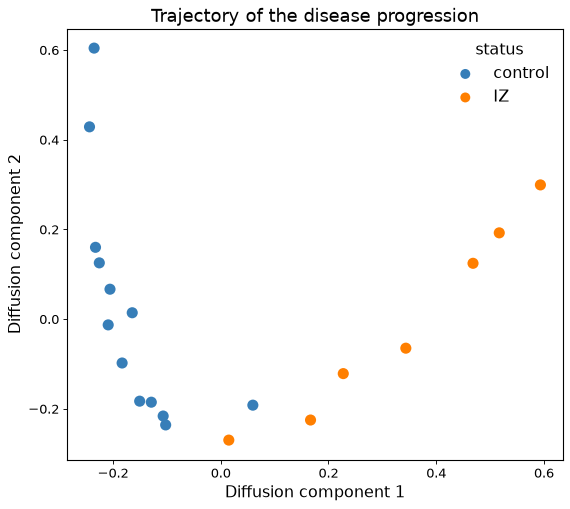

In [ ]:
adata = sc.read_h5ad('Datasets/myocardial_infarction.h5ad')
pl.tl.wasserstein_distance(
    adata,
    emb_matrix = 'PCA',
    clusters_col = 'cell_subtype',
    sample_col = 'sampleID',
    status = 'Status',
    )
pl.pl.trajectory(adata)

Root of the trajectory: node 7 (end node where the control samples come first).

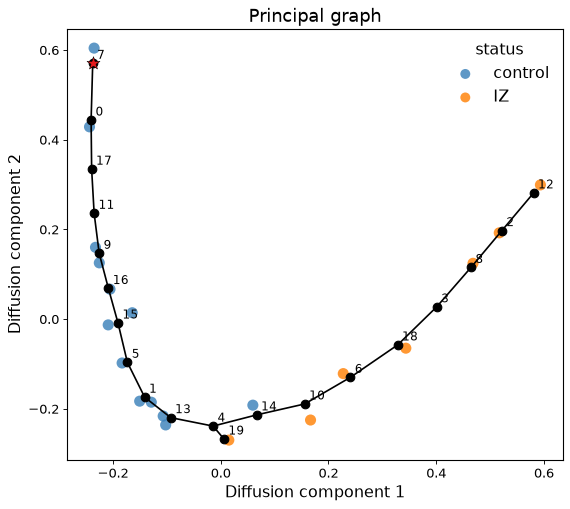

In [ ]:
pl.pl.fit_pricipla_graph(adata, source_node = 'auto', root_status = 'control')

In [ ]:
pl.tl.cell_importance_calculation(adata)

##### Export:
<div class="alert alert-block alert-info">
`pl.tl.to_mudata` puts the results in a MuData object and, with `path`, also writes it to a `.h5mu` file. The `samples` modality has one row per sample:

- `X`: the cell type proportions (samples x cell types);
- `obs`: the status and the clinical variables, the pseudotime, the position on the trajectory and the principal graph node (and the clusters, if computed);
- `obsm`: the trajectory (`X_trajectory`) and the sample UMAP (`X_umap`, if computed);
- `obsp['wasserstein']`: the Wasserstein distances between the samples;
- `varp['cost']`: the cost matrix between the cell types;
- `uns['pilot']`: the settings and the principal graph.
</div>

In [ ]:
mdata = pl.tl.to_mudata(adata, path = 'Results_PILOT/MI_PILOT.h5mu')
mdata

MuData object with n_obs × n_vars = 115537 × 28441
  uns:	'pilot_modalities'
  2 modalities
    cells:	115517 × 28408
      obs:	'orig_ident', 'nCount_RNA', 'nFeature_RNA', 'percent_mt', 'doublet_score', 'doublet', 'dissociation_s1', 'opt_clust', 'patient', 'batch', 'opt_clust_integrated', 'cell_type', 'ident', 'n_genes', 'cell_subtype', 'cell_subtype_available', 'cell_subtype2', 'sampleID', 'patient_group', 'Status'
      obsm:	'HARMONY', 'PCA', 'UMAP_HARMONY'
      layers:	'logcounts'
    samples:	20 × 33
      obs:	'status', 'doublet', 'patient', 'batch', 'cell_subtype_available', 'patient_group', 'Status', 'pseudotime', 'graph_node', 'trajectory_order'
      uns:	'pilot'
      obsm:	'X_trajectory'
      obsp:	'wasserstein'
      varp:	'cost'

In [ ]:
mdata['samples'].obs.head()

,status,doublet,patient,batch,cell_subtype_available,patient_group,Status,pseudotime,graph_node,trajectory_order
control_P1,control,singlet,P1,A,yes,myogenic,control,0.823557,13,12
RZ_FZ_P5,control,singlet,P5,A,yes,myogenic,control,0.810914,13,11
RZ_BZ_P3,control,singlet,P3,A,yes,myogenic,control,0.567274,15,6
RZ_BZ_P2,control,singlet,P2,A,yes,myogenic,control,0.584191,15,7
RZ_P3,control,singlet,P3,A,yes,myogenic,control,0.988766,14,14


In [ ]:
mdata['samples'].obsp['wasserstein'].shape

(20, 20)

##### Only the patient level:
<div class="alert alert-block alert-info">
With `include_cells = False` only the `samples` modality is kept. The file is then very small and can be shared easily (no single-cell data in it). You can also get the patient-level AnnData directly with `pl.tl.sample_adata(adata)`.
</div>

In [ ]:
samples_only = pl.tl.to_mudata(adata, include_cells = False, path = 'Results_PILOT/MI_PILOT_samples.h5mu')
samples_only

MuData object with n_obs × n_vars = 20 × 33
  uns:	'pilot_modalities'
  1 modality
    samples:	20 × 33
      obs:	'status', 'doublet', 'patient', 'batch', 'cell_subtype_available', 'patient_group', 'Status', 'pseudotime', 'graph_node', 'trajectory_order'
      uns:	'pilot'
      obsm:	'X_trajectory'
      obsp:	'wasserstein'
      varp:	'cost'

##### Import:
<div class="alert alert-block alert-info">
`pl.tl.from_mudata` reads the file and returns the cells with the PILOT results restored (Wasserstein distances, trajectory, principal graph, pseudotime). The next steps work directly; for example the trajectory is not computed again.
</div>

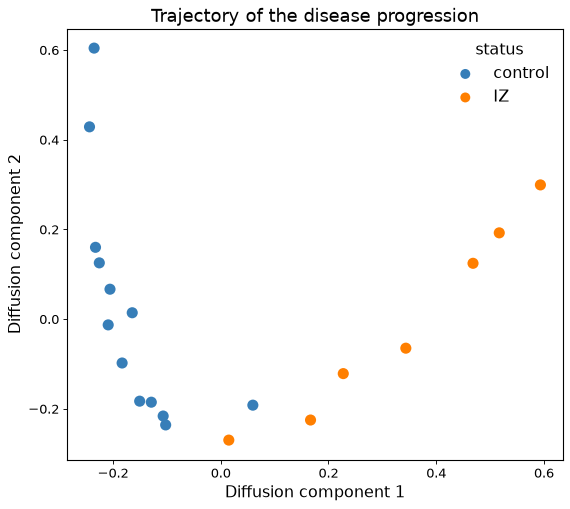

In [ ]:
adata_loaded = pl.tl.from_mudata('Results_PILOT/MI_PILOT.h5mu')
pl.pl.trajectory(adata_loaded)

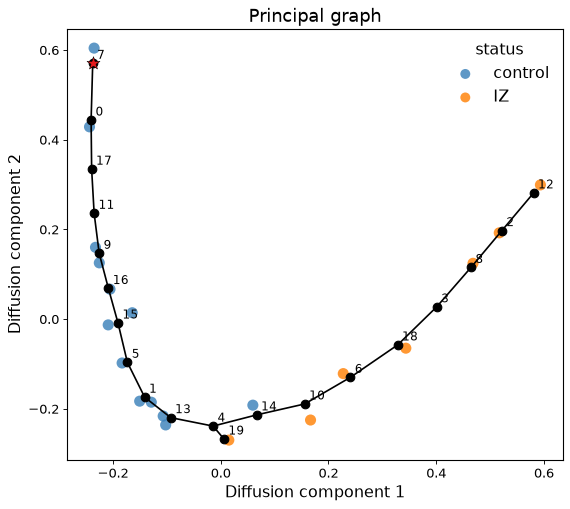

In [ ]:
pl.pl.principal_graph(adata_loaded)

##### A MuData as input:
<div class="alert alert-block alert-info">
If your data is already a MuData (e.g. RNA and protein of CITE-seq, or RNA and ATAC), give it to `pl.tl.wasserstein_distance` and choose the modality with the cells with `modality`. Clinical variables in the global `mdata.obs` are copied to the modality. The results are stored in that modality, so continue with `mdata['rna']`.
</div>

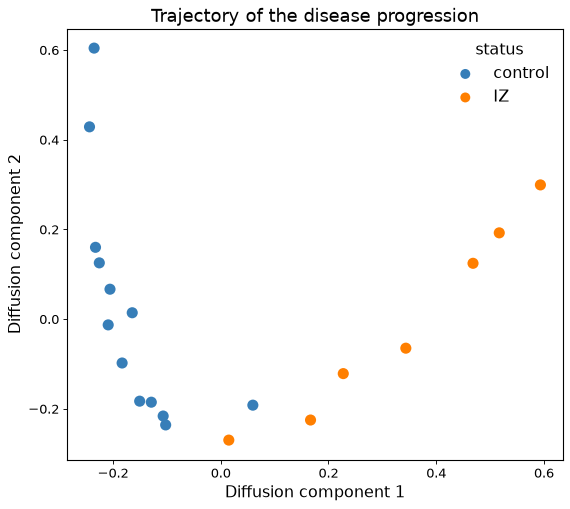

In [ ]:
rna = sc.read_h5ad('Datasets/myocardial_infarction.h5ad')
mdata_input = md.MuData({'rna': rna})

pl.tl.wasserstein_distance(
    mdata_input,
    modality = 'rna',
    emb_matrix = 'PCA',
    clusters_col = 'cell_subtype',
    sample_col = 'sampleID',
    status = 'Status',
    )
adata_rna = mdata_input['rna']
pl.pl.trajectory(adata_rna)